<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter6/velocity_hodograph.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Simple Pendulum Velocity Hodograph.

<>:83: SyntaxWarning: invalid escape sequence '\d'
<>:84: SyntaxWarning: invalid escape sequence '\d'
<>:165: SyntaxWarning: invalid escape sequence '\p'
<>:195: SyntaxWarning: invalid escape sequence '\p'
<>:202: SyntaxWarning: invalid escape sequence '\p'
<>:202: SyntaxWarning: invalid escape sequence '\c'
<>:225: SyntaxWarning: invalid escape sequence '\c'
<>:226: SyntaxWarning: invalid escape sequence '\c'
<>:227: SyntaxWarning: invalid escape sequence '\c'
<>:228: SyntaxWarning: invalid escape sequence '\c'
<>:245: SyntaxWarning: invalid escape sequence '\c'
<>:246: SyntaxWarning: invalid escape sequence '\c'
<>:83: SyntaxWarning: invalid escape sequence '\d'
<>:84: SyntaxWarning: invalid escape sequence '\d'
<>:165: SyntaxWarning: invalid escape sequence '\p'
<>:195: SyntaxWarning: invalid escape sequence '\p'
<>:202: SyntaxWarning: invalid escape sequence '\p'
<>:202: SyntaxWarning: invalid escape sequence '\c'
<>:225: SyntaxWarning: invalid escape sequence '\c'
<>:226: SyntaxWa

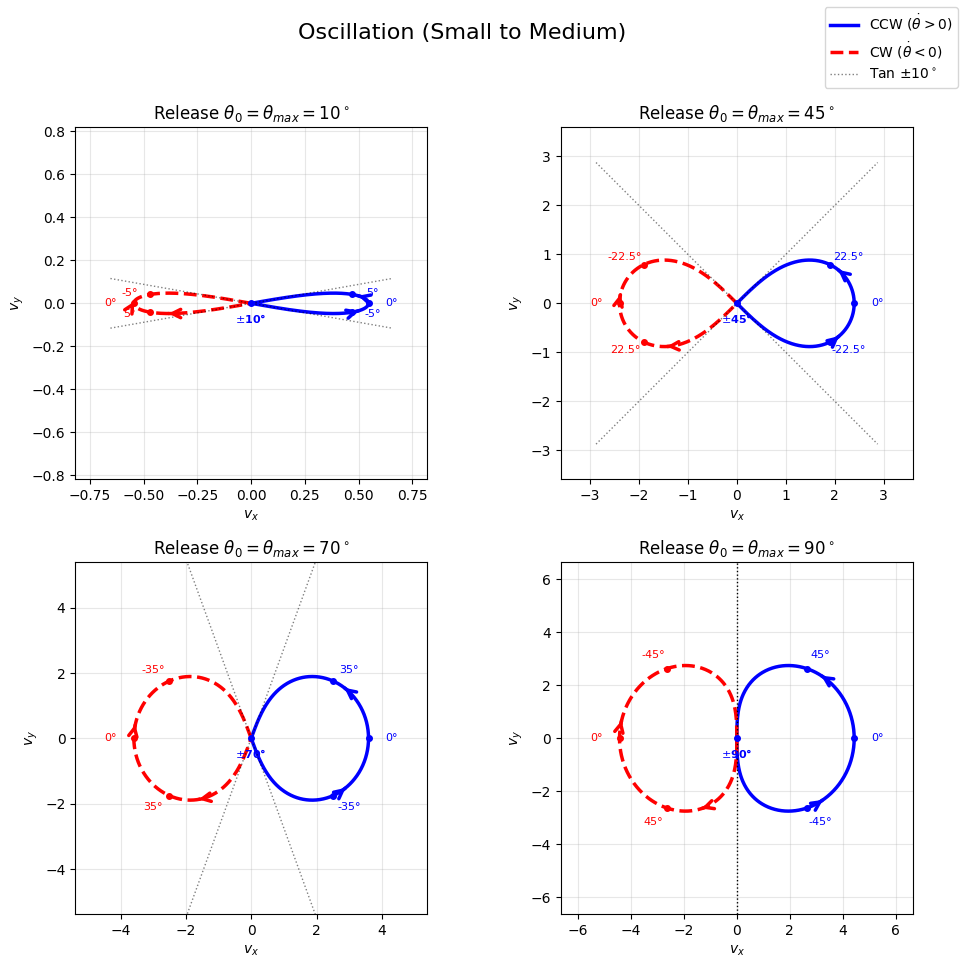

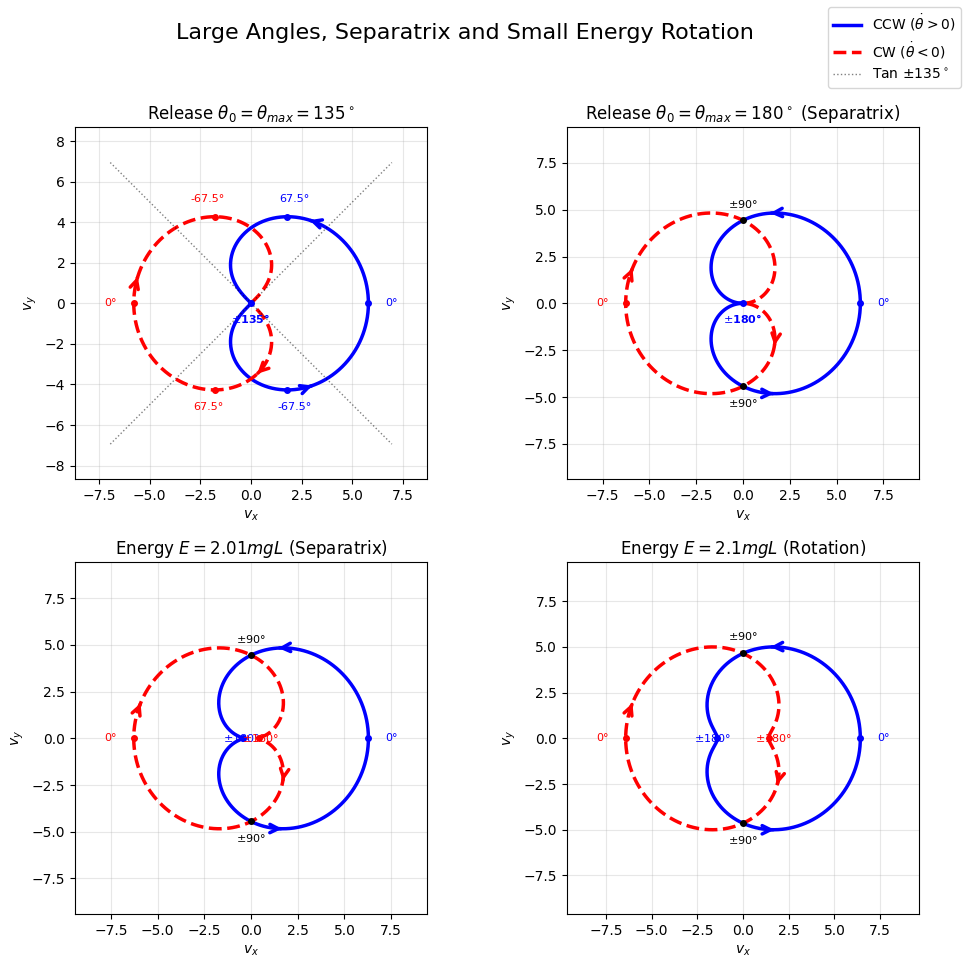

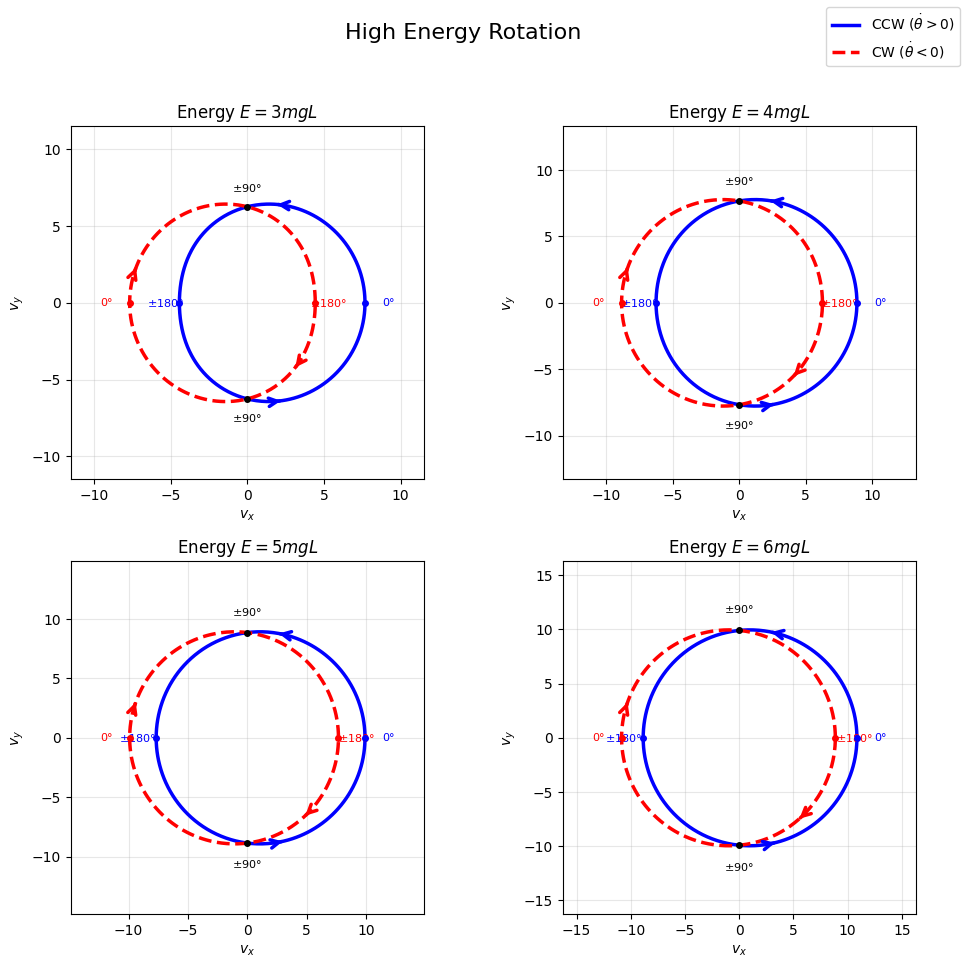

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def get_pendulum_dynamics(g, L, theta_max_deg=None, energy_factor=None):
    """
    Calculates phase space dynamics.
    Returns dictionary with CW and CCW velocity branches.
    """
    if theta_max_deg is not None:
        # Oscillation Case
        theta_max = np.radians(theta_max_deg)
        E_dimless = 1 - np.cos(theta_max)
        theta = np.linspace(-theta_max, theta_max, 500)
    else:
        # Rotation Case
        E_dimless = energy_factor
        theta = np.linspace(-np.pi, np.pi, 500)

    # v^2/gL = 2 * (E_dimless - (1 - cos(theta)))
    metric = E_dimless - (1 - np.cos(theta))
    metric[metric < 0] = 0
    v_mag = np.sqrt(2 * g * L * metric)

    # Decompose components
    # CCW (theta_dot > 0): Tangent is +90 deg relative to radial vector
    vx_ccw = v_mag * np.cos(theta)
    vy_ccw = v_mag * np.sin(theta)

    # CW (theta_dot < 0): Tangent is -90 deg relative to radial vector
    vx_cw = -v_mag * np.cos(theta)
    vy_cw = -v_mag * np.sin(theta)

    return {
        'theta': theta,
        'vx_ccw': vx_ccw, 'vy_ccw': vy_ccw,
        'vx_cw': vx_cw, 'vy_cw': vy_cw,
        'v_max': np.max(v_mag) if len(v_mag) > 0 else 1.0,
        'E_dimless': E_dimless
    }

def add_arrow(line, position=None, direction='right', size=15, color=None, reverse=False):
    """
    Add an arrow to a line.
    reverse=True means draw arrow from idx+1 to idx (against array order).
    """
    if color is None:
        color = line.get_color()

    xdata = line.get_xdata()
    ydata = line.get_ydata()

    if len(xdata) < 2: return

    if position is None:
        position = xdata.mean()
        idx = (np.abs(xdata - position)).argmin()
    else:
        idx = position

    if idx >= len(xdata) - 1: idx = len(xdata) - 2

    start_x = xdata[idx]
    start_y = ydata[idx]
    end_x = xdata[idx+1]
    end_y = ydata[idx+1]

    # If reverse (e.g., for CW motion where theta decreases but array increases), swap start/end
    if reverse:
        start_x, end_x = end_x, start_x
        start_y, end_y = end_y, start_y

    line.axes.annotate('',
        xytext=(start_x, start_y),
        xy=(end_x, end_y),
        arrowprops=dict(arrowstyle="->", color=color, lw=2.5),
        size=size
    )

def plot_hodograph(ax, g, L, angle=None, energy=None, title=""):
    data = get_pendulum_dynamics(g, L, theta_max_deg=angle, energy_factor=energy)

    # Plot curves
    l1, = ax.plot(data['vx_ccw'], data['vy_ccw'], 'b-', lw=2.5,label='CCW ($\dot{\\theta}>0$)')
    l2, = ax.plot(data['vx_cw'], data['vy_cw'], 'r--', lw=2.5,label='CW ($\dot{\\theta}<0$)')

    # Add Staggered Arrows
    # Stagger indices to avoid overlap between Blue (CCW) and Red (CW) arrows
    if len(data['theta']) > 10:
        n = len(data['theta'])

        # CCW (Blue): Motion follows array order. Placed at 30% and 70%.
        idx_b1 = int(n * 0.30)
        idx_b2 = int(n * 0.70)
        add_arrow(l1, position=idx_b1, color='b', reverse=False)
        add_arrow(l1, position=idx_b2, color='b', reverse=False)

        # CW (Red): Motion is opposite to array order. Placed at 45% and 85%.
        # reverse=True ensures arrow points in direction of time (decreasing theta)
        idx_r1 = int(n * 0.45)
        idx_r2 = int(n * 0.85)
        add_arrow(l2, position=idx_r1, color='r', reverse=True)
        add_arrow(l2, position=idx_r2, color='r', reverse=True)

    # --- Add Smart Angle Markers ---
    points_to_plot = []

    if angle is not None:
        marker_angles = [-angle, -angle/2, 0, angle/2, angle]
    else:
        marker_angles = [-180, -90, 0, 90, 180]

    E_dimless = data['E_dimless']

    # 1. Generate all marker coordinates
    for deg in marker_angles:
        rad = np.radians(deg)
        metric = E_dimless - (1 - np.cos(rad))
        if metric < 0: metric = 0
        v = np.sqrt(2 * g * L * metric)

        # CCW Branch
        vx_ccw = v * np.cos(rad)
        vy_ccw = v * np.sin(rad)
        points_to_plot.append({'x': vx_ccw, 'y': vy_ccw, 'deg': deg, 'color': 'blue'})

        # CW Branch
        if v > 1e-3:
            vx_cw = -vx_ccw
            vy_cw = -vy_ccw
            points_to_plot.append({'x': vx_cw, 'y': vy_cw, 'deg': deg, 'color': 'red'})

    # 2. Merge overlapping points
    unique_points = []
    tolerance = data['v_max'] * 0.05

    for p in points_to_plot:
        match = None
        for up in unique_points:
            dist = np.sqrt((p['x'] - up['x'])**2 + (p['y'] - up['y'])**2)
            if dist < tolerance:
                match = up
                break

        if match:
            if p['deg'] not in match['labels']:
                match['labels'].append(p['deg'])
            match['colors'].add(p['color'])
        else:
            unique_points.append({
                'x': p['x'],
                'y': p['y'],
                'labels': [p['deg']],
                'colors': {p['color']}
            })

    # 3. Plot unique points
    for p in unique_points:
        labels = sorted(p['labels'])
        final_parts = []
        processed = set()

        for val in labels:
            if val in processed: continue
            if -val in labels and val != 0:
                final_parts.append(f"$\pm${abs(val):g}°")
                processed.add(val)
                processed.add(-val)
            else:
                final_parts.append(f"{val:g}°")
                processed.add(val)

        label_text = "\n".join(final_parts)

        colors = list(p['colors'])
        if len(colors) > 1:
            pt_color = 'black'
            txt_color = 'black'
        else:
            pt_color = colors[0]
            txt_color = colors[0]

        ax.plot(p['x'], p['y'], 'o', color=pt_color, markersize=4, zorder=10)

        dist_from_origin = np.sqrt(p['x']**2 + p['y']**2)
        if dist_from_origin < tolerance:
            ax.text(p['x'], p['y'] - tolerance*1.5, label_text, fontsize=8, ha='center', va='top', color=txt_color, fontweight='bold', zorder=10)
        else:
            factor = 1.2
            ax.text(p['x']*factor, p['y']*factor, label_text, fontsize=8, ha='center', va='center', color=txt_color, zorder=10)

    # Tangents for Oscillation
    if angle is not None and angle < 180:
        if abs(angle - 90) < 1.0:
            limit_y = data['v_max'] * 1.5
            ax.vlines(0, -limit_y, limit_y, colors='k', linestyles=':', linewidth=1, label='Tan $\pm 90^\circ$')
        else:
            theta_rad = np.radians(angle)
            slope = np.tan(theta_rad)
            limit_x = data['v_max'] * 1.2
            if abs(slope) > 2: limit_x = limit_x / abs(slope) * 2
            x_tan = np.linspace(-limit_x, limit_x, 100)
            ax.plot(x_tan, x_tan * slope, 'k:', alpha=0.5, linewidth=1, label=f'Tan $\pm{angle}^\circ$')
            ax.plot(x_tan, x_tan * (-slope), 'k:', alpha=0.5, linewidth=1)

    ax.set_title(title)
    ax.set_xlabel('$v_x$')
    ax.set_ylabel('$v_y$')
    ax.grid(True, alpha=0.3)

    limit = data['v_max'] * 1.5
    if limit < 0.1: limit = 1.0
    ax.set_xlim(-limit, limit)
    ax.set_ylim(-limit, limit)
    ax.set_aspect('equal', adjustable='box')

# --- Main Execution ---
g = 9.81
L = 1.0

# --- Figure 1: Oscillation ---
fig1, axs1 = plt.subplots(2, 2, figsize=(10, 10))
fig1.suptitle("Oscillation (Small to Medium)", fontsize=16)

cases_fig1 = [
    (10, None, "Release $\\theta_0 = \\theta_{max}=10^\circ$"),
    (45, None, "Release $\\theta_0 = \\theta_{max}=45^\circ$"),
    (70, None, "Release $\\theta_0 = \\theta_{max}=70^\circ$"),
    (90, None, "Release $\\theta_0 = \\theta_{max}=90^\circ$")
]

for ax, (ang, en, tit) in zip(axs1.flat, cases_fig1):
    plot_hodograph(ax, g, L, angle=ang, energy=en, title=tit)

# ADD LEGEND FOR FIG 1
handles, labels = axs1[0,0].get_legend_handles_labels()
if handles: fig1.legend(handles, labels, loc='upper right')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# --- Figure 2: Large Angles & Transition ---
fig2, axs2 = plt.subplots(2, 2, figsize=(10, 10))
fig2.suptitle("Large Angles, Separatrix and Small Energy Rotation", fontsize=16)

cases_fig2 = [
    (135, None, "Release $\\theta_0 = \\theta_{max}=135^\circ$"),
    (180, None, "Release $\\theta_0 = \\theta_{max}=180^\circ$ (Separatrix)"),
    (None, 2.01, "Energy $E = 2.01mgL$ (Separatrix)"),
    (None, 2.1, "Energy $E = 2.1mgL$ (Rotation)")
]

for ax, (ang, en, tit) in zip(axs2.flat, cases_fig2):
    plot_hodograph(ax, g, L, angle=ang, energy=en, title=tit)

# ADD LEGEND FOR FIG 2
handles, labels = axs2[0,0].get_legend_handles_labels()
if handles: fig2.legend(handles, labels, loc='upper right')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# --- Figure 3: High Energy Rotation ---
fig3, axs3 = plt.subplots(2, 2, figsize=(10, 10))
fig3.suptitle("High Energy Rotation", fontsize=16)

cases_fig3 = [
    (None, 3.0, "Energy $E = 3mgL$"),
    (None, 4.0, "Energy $E = 4mgL$"),
    (None, 5.0, "Energy $E = 5mgL$"),
    (None, 6.0, "Energy $E = 6mgL$")
]

for ax, (ang, en, tit) in zip(axs3.flat, cases_fig3):
    plot_hodograph(ax, g, L, angle=ang, energy=en, title=tit)

# ADD LEGEND FOR FIG 3
handles, labels = axs3[0,0].get_legend_handles_labels()
if handles: fig3.legend(handles, labels, loc='upper right')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()